# 02 · Charger un CSV et le trier

C'est le livrable principal : on donne au bot un fichier CSV de tickets, il renvoie le même fichier avec
ses réponses, et des métriques si les bonnes réponses sont dans le fichier.

Ce notebook :
1. lit `data/demo/demo15.csv` (15 tickets tirés de val60) ;
2. montre la commande `make triage` et le code qu'elle lance ;
3. affiche le CSV de sortie **enregistré** et recalcule les métriques.

**On ne relance pas le tri ici** : le notebook n'appelle aucun modèle. La sortie affichée est celle du run
du 24/09/2026 (`data/demo/demo15_triage.csv` et `.md`), faite avec le bot du tag `v7-final`.

In [1]:
import re
import pandas as pd
import matplotlib.pyplot as plt
from outils import REPO, figure, finish, sobre, kpi, pct, TEXTE, GRIS, GRIS_FONCE, BLEU

pd.set_option("display.max_colwidth", 80)

## 1. Le CSV d'entrée

Une seule colonne est obligatoire : `ticket`, le texte du client. Ici, le fichier contient aussi les bonnes
réponses (`categorie`, `produit`, `severite`), ce qui permet de calculer des métriques.

In [2]:
entree = pd.read_csv(REPO / "data/demo/demo15.csv")
print(entree.shape[0], "tickets, colonnes :", list(entree.columns))
entree.head()

15 tickets, colonnes : ['id', 'ticket', 'categorie', 'produit', 'severite']


,id,ticket,categorie,produit,severite
0,VAL001,"Bonjour, je pars sur un chantier en Suisse pendant trois semaines. Est-ce qu...",other,card,low
1,VAL002,"Madame, Monsieur,\nDepuis vendredi, mon compte est bloqué à la suite d'une «...",bug,account,high
2,VAL004,bonjour prelevement de 312 euros de ma mutuelle passé 2 fois ce mois ci vous...,billing,direct_debit,high
3,VAL009,"- paiement carte de 212,40 € « FLX*DIGITALGOODS » le 14/11\n- ce n'est pas m...",billing,card,high
4,VAL013,Mandat de prélèvement EDF toujours refusé par l'appli. Encore.,bug,direct_debit,medium


## 2. La commande

```bash
make triage CSV=data/demo/demo15.csv            # garde d'entrée, tri, contrôle
make triage CSV=data/demo/demo15.csv BROUILLON=1 # + brouillon de réponse
```

`make triage` lance simplement ce script (règle du `Makefile`) :

In [3]:
makefile = (REPO / "Makefile").read_text(encoding="utf-8")
print(re.search(r"^triage:.*?(?=^\S|\Z)", makefile, flags=re.M | re.S).group(0))

triage:
	@test -n "$(CSV)" || (echo "Usage : make triage CSV=chemin.csv [BROUILLON=1]" && exit 2)
	@ollama list >/dev/null 2>&1 || true   # réveille Ollama s'il dort
	$(RUN) eval/triage_csv.py "$(CSV)" $(if $(BROUILLON),--brouillon)




Le script `eval/triage_csv.py` traite le fichier **étape par étape** : tous les tris, puis tous les contrôles,
puis (option) tous les brouillons. Un seul modèle est chargé à la fois, ce qui évite de recharger 5 Go de
modèle entre deux tickets. Voici le cœur du traitement, la fonction `process` :

In [4]:
code = (REPO / "eval/triage_csv.py").read_text(encoding="utf-8")
debut = code.index("def process(")
fin = code.index("    drafts = [None]", debut)
print(code[debut:fin])

def process(rows: list[dict], with_draft: bool, received_default: str, progress: Progress,
            on_triage=None, trace=None) -> list[dict]:
    """`on_triage(k, fields)`, si fourni, reçoit le tri de chaque ticket dès qu'il est connu (console).

    `trace(step, k, call)`, si fourni, exécute `call()` et renvoie son résultat tel quel : la console
    s'en sert pour enregistrer chaque étape d'un ticket (api/trace.py). Sans lui, `call()` directement.
    """
    run = trace or (lambda step, k, call: call())
    ids = [r.get("id") or f"#{n}" for n, r in enumerate(rows, start=1)]
    tickets = [{"id": ids[k], "input": r["ticket"], "channel": r.get("canal") or "form",
                "received_at": r.get("recu_le") or received_default} for k, r in enumerate(rows)]

    progress.begin("tri")   # garde d'entrée + llama
    tri = []
    for k, t in enumerate(tickets):
        tri.append(run("tri", k, lambda: triage.triage(t["input"])))
        if on_triage:
            on_triage(k, tri[k][

Pour chaque ticket :
- `triage.triage` : la **garde d'entrée** (code) retire les injections repérées, puis **llama3.1:8b** remplit
  les champs avec le prompt v7 ;
- `controller.predict` : **qwen2.5:7b** redonne le sous-motif, pour vérifier le tri ;
- `compute_deadlines` : le **code** calcule l'échéance réglementaire.

## 3. Le CSV de sortie (enregistré)

Les colonnes d'entrée, puis les réponses du bot.

In [5]:
sortie = pd.read_csv(REPO / "data/demo/demo15_triage.csv")
colonnes = ["id", "categorie", "categorie_predite", "produit", "produit_predit", "severite", "severite_predite",
            "sous_motif", "reclamation", "injection_suspectee", "echeance", "controle"]
sortie[colonnes]

,id,categorie,categorie_predite,produit,produit_predit,severite,severite_predite,sous_motif,reclamation,injection_suspectee,echeance,controle
0,VAL001,other,other,card,card,low,low,question_carte,non,non,2026-09-28,accord
1,VAL002,bug,bug,account,account,high,high,compte_bloque,oui,non,2026-10-08,accord
2,VAL004,billing,billing,direct_debit,direct_debit,high,high,debit_errone,oui,non,2026-10-08,accord
3,VAL009,billing,billing,card,card,high,high,operation_non_autorisee,oui,non,2026-09-25,accord
4,VAL013,bug,bug,direct_debit,direct_debit,medium,medium,probleme_prelevement,oui,non,2026-10-08,accord
5,VAL015,bug,bug,transfer,transfer,medium,medium,virement_non_arrive,oui,non,2026-10-08,accord
6,VAL024,billing,billing,card,card,medium,low,question_debit,non,non,2026-09-28,désaccord
7,VAL029,bug,bug,card,card,medium,medium,carte_refusee,non,oui,2026-09-28,accord
8,VAL036,other,other,unknown,unknown,medium,low,autre,oui,non,2026-10-08,accord
9,VAL040,other,other,unknown,unknown,low,low,autre,non,non,2026-09-28,désaccord


### Métriques, recalculées depuis le CSV

Un champ est juste quand la prédiction est égale à la bonne réponse.

In [6]:
CHAMPS = {"categorie": "categorie_predite", "produit": "produit_predit", "severite": "severite_predite"}
justes = pd.DataFrame({c: sortie[c] == sortie[p] for c, p in CHAMPS.items()})
justes["tout juste"] = justes.all(axis=1)
precision = justes.mean()
pd.DataFrame({"justes": justes.sum(), "sur": len(sortie), "précision": precision.map(pct)})

,justes,sur,précision
categorie,14,15,"93,3 %"
produit,14,15,"93,3 %"
severite,13,15,"86,7 %"
tout juste,11,15,"73,3 %"


In [7]:
for c, p in CHAMPS.items():
    print(f"\n{c} (lignes : bonne réponse, colonnes : prédiction)")
    print(pd.crosstab(sortie[c], sortie[p]))


categorie (lignes : bonne réponse, colonnes : prédiction)
categorie_predite  billing  bug  other
categorie                             
billing                  3    0      1
bug                      0    6      0
other                    0    0      5

produit (lignes : bonne réponse, colonnes : prédiction)
produit_predit  account  card  direct_debit  transfer  unknown
produit                                                       
account               2     0             0         0        0
card                  0     5             0         0        0
direct_debit          0     0             2         0        0
transfer              1     0             0         3        0
unknown               0     0             0         0        2

severite (lignes : bonne réponse, colonnes : prédiction)
severite_predite  high  low  medium
severite                           
high                 4    0       0
low                  0    5       0
medium               0    2       4


In [8]:
sortie.loc[~justes["tout juste"], ["id", "categorie", "categorie_predite", "produit", "produit_predit",
                                   "severite", "severite_predite"]]

,id,categorie,categorie_predite,produit,produit_predit,severite,severite_predite
6,VAL024,billing,billing,card,card,medium,low
8,VAL036,other,other,unknown,unknown,medium,low
10,VAL042,billing,other,transfer,transfer,low,low
13,VAL052,other,other,transfer,account,low,low


Le rapport écrit par le script au moment du run donne la durée :

In [9]:
rapport = (REPO / "data/demo/demo15_triage.md").read_text(encoding="utf-8")
print("\n".join(rapport.splitlines()[:9]))
duree = re.search(r"Durée : (.+?) \((.+?) s par ticket\)", rapport)
duree_totale, par_ticket = duree.group(1), duree.group(2)

# Tri de demo15.csv

- Tickets : 15
- Étapes : tri, contrôle
- Modèles : tri llama3.1:8b, contrôleur qwen2.5:7b
- Durée : 1 min 35 s (6,3 s par ticket)
- Lancé le : 2026-09-24 14:10:33
- Sortie : demo15_triage.csv



In [10]:
n_ok = int(justes["tout juste"].sum())
kpi("demo15_tout_juste", {"justes": n_ok, "n": len(sortie)},
    "tickets de demo15 entièrement justes (catégorie + produit + gravité)",
    "data/demo/demo15_triage.csv (run enregistré du 24/09/2026)", "03_demo15.png")
kpi("demo15_duree", {"total": duree_totale, "par_ticket_s": float(par_ticket.replace(",", "."))},
    "durée de make triage sur demo15, modèles froids", "data/demo/demo15_triage.md", "03_demo15.png")

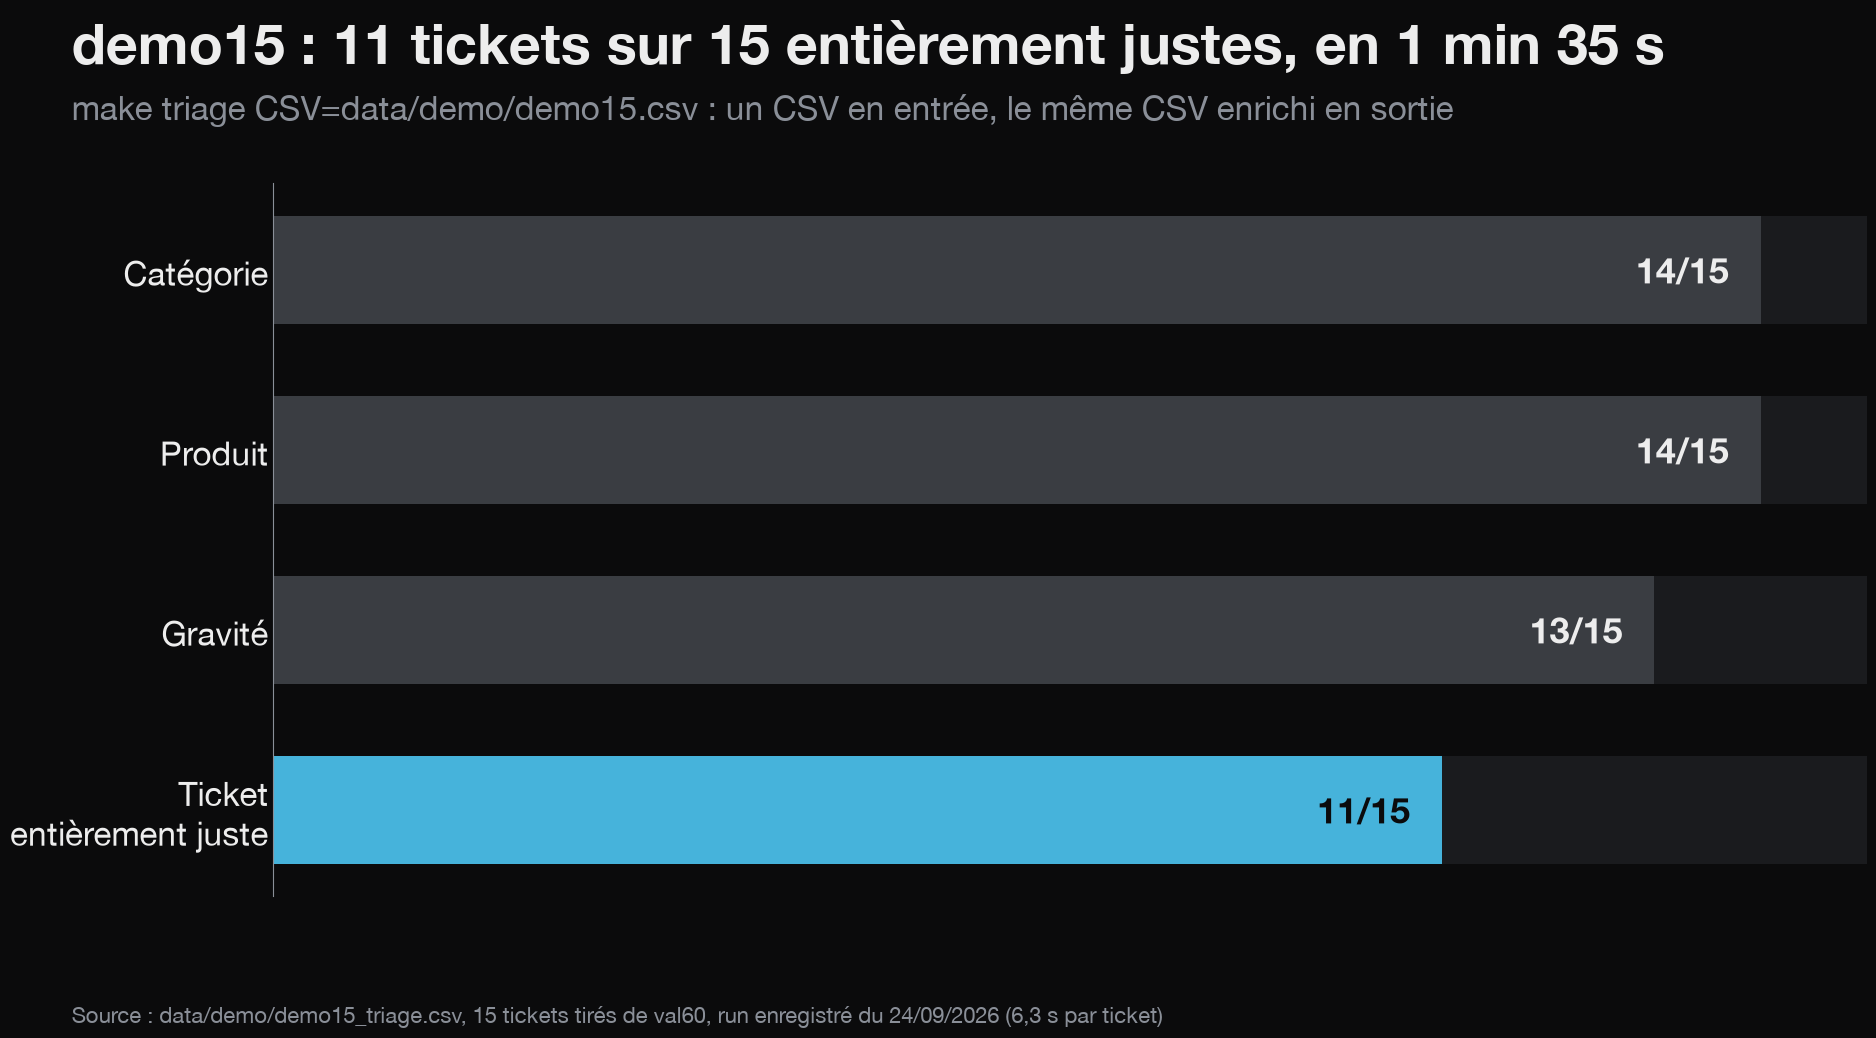

In [11]:
fig, ax = figure(left=0.14)
noms = {"categorie": "Catégorie", "produit": "Produit", "severite": "Gravité", "tout juste": "Ticket\nentièrement juste"}
ordre = list(noms)[::-1]
vals = [justes[c].sum() for c in ordre]
ax.barh([noms[c] for c in ordre], vals, color=[BLEU if c == "tout juste" else GRIS_FONCE for c in ordre], height=0.6)
ax.barh([noms[c] for c in ordre], [len(sortie) - v for v in vals], left=vals, color="#1A1B1E", height=0.6)
for y, (c, v) in enumerate(zip(ordre, vals)):
    ax.text(v - 0.3, y, f"{v}/15", va="center", ha="right", fontsize=26, weight="bold",
            color="#0B0B0C" if c == "tout juste" else TEXTE)
ax.set_xlim(0, 15)
ax.set_xticks([])
ax.spines["bottom"].set_visible(False)
ax.tick_params(axis="y", labelsize=24, labelcolor=TEXTE)
sobre(ax)
finish(fig, 3, "demo15", f"demo15 : {n_ok} tickets sur 15 entièrement justes, en {duree_totale}",
       f"data/demo/demo15_triage.csv, 15 tickets tirés de val60, run enregistré du 24/09/2026 ({par_ticket} s par ticket)",
       "make triage CSV=data/demo/demo15.csv : un CSV en entrée, le même CSV enrichi en sortie")
plt.show()